# Неделя 21. Контекст и память чат-бота

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** построить настоящий локальный TF-IDF retrieval, измерить Recall@k и сделать chatbot с изолированными сессиями.

**Режим:** retrieval вычисляется реально; ответы извлекаются из документов дословно. Это extractive baseline, не генеративная LLM. API-мост вынесен в отдельный optional-скрипт.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_21_context_memory"
DATA = WEEK / "datasets"
SEED = 121
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Память и база знаний решают разные задачи

Память хранит контекст диалога, knowledge — проверяемые сведения. Сама история не обновляет знания модели. Наши документы — вымышленный учебный регламент, не официальный регламент Tech Orda.


,doc_id,title,characters,updated_at
0,K01,Расписание,108,2026-10-18
1,K02,Домашняя работа,113,2026-10-18
2,K03,Python,112,2026-10-18
3,K04,Оплата,140,2026-10-18
4,K05,Вход,146,2026-10-18
5,K06,Проект,121,2026-10-18
6,K07,Пропуск,129,2026-10-18
7,K08,Оценивание,138,2026-10-18
8,K09,Данные,139,2026-10-18
9,K10,GPU,105,2026-10-18


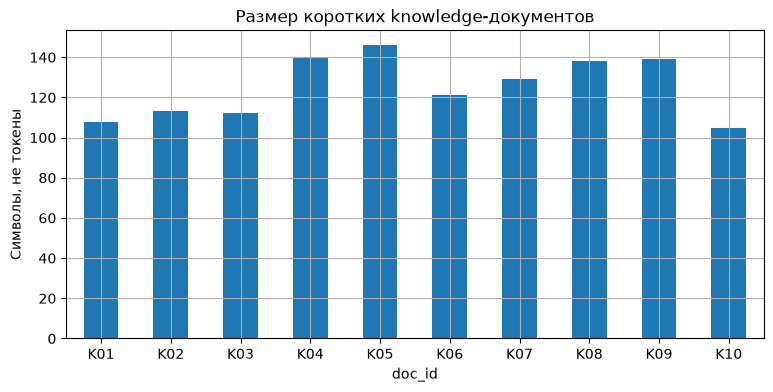

In [2]:
docs = pd.DataFrame(json.loads((DATA / 'knowledge.json').read_text(encoding='utf-8')))
evaluation = pd.read_csv(DATA / 'retrieval_eval.csv')
docs['characters'] = docs.text.str.len()
assert docs.doc_id.is_unique and evaluation.relevant_doc.isin(docs.doc_id).all()
display(docs[['doc_id', 'title', 'characters', 'updated_at']])
docs.plot.bar(x='doc_id', y='characters', legend=False, rot=0, title='Размер коротких knowledge-документов')
plt.ylabel('Символы, не токены'); plt.show()


## 2. TF-IDF и cosine similarity

      $\operatorname{tfidf}(t,d)=\operatorname{tf}(t,d)\operatorname{idf}(t)$.
      Cosine similarity сравнивает направления векторов: $q\cdot d/(\|q\|\|d\|)$.
      Используем char n-grams, чтобы частично учитывать русские окончания. Это lexical retrieval,
      он не обучает семантическую embedding-модель и может пропускать синонимы.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), lowercase=True)
matrix = vectorizer.fit_transform(docs.title + ' ' + docs.text)
assert matrix.shape[0] == len(docs)
print('Документов:', matrix.shape[0], 'n-gram признаков:', matrix.shape[1])
def retrieve(query, k=3):
    if not query.strip():
        return docs.iloc[:0].assign(score=pd.Series(dtype=float))
    scores = cosine_similarity(vectorizer.transform([query]), matrix).ravel()
    indices = np.argsort(-scores, kind='stable')[:k]
    return docs.iloc[indices].assign(score=scores[indices])
display(retrieve('Как восстановить пароль?')[['doc_id', 'title', 'score']])


Документов: 10 n-gram признаков: 2174


,doc_id,title,score
4,K05,Вход,0.383804
7,K08,Оценивание,0.080516
8,K09,Данные,0.015573


## 3. Recall@k на независимых формулировках

Для каждого вопроса указан один релевантный документ. В этом частном случае Recall@k равен доле запросов, у которых нужный doc_id попал в top-k. Это метрика поиска, не правильности сгенерированного ответа.


,k,recall_at_k,n
0,1,1.0,10
1,2,1.0,10
2,3,1.0,10
3,5,1.0,10


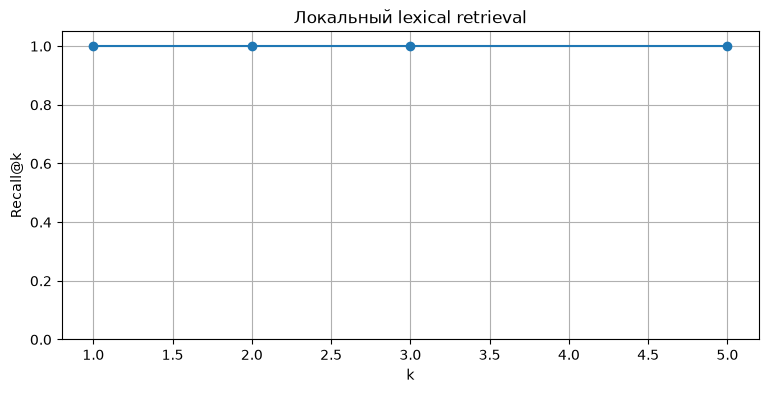

In [4]:
recall_rows = []
for k in [1, 2, 3, 5]:
    hits = [row.relevant_doc in set(retrieve(row.query, k).doc_id) for row in evaluation.itertuples()]
    recall_rows.append({'k': k, 'recall_at_k': np.mean(hits), 'n': len(hits)})
recall_table = pd.DataFrame(recall_rows)
display(recall_table)
assert recall_table.recall_at_k.is_monotonic_increasing
recall_table.plot(x='k', y='recall_at_k', marker='o', ylim=(0, 1.05), legend=False)
plt.title('Локальный lexical retrieval'); plt.ylabel('Recall@k'); plt.show()


## 4. Разбор промахов

Высокий Recall@5 может скрывать слабое ранжирование на маленьком корпусе из 10 документов. Посмотрим top-1, ожидаемый документ и score. Не подгоняйте порог по единственному вопросу.


In [5]:
ranking = []
for row in evaluation.itertuples():
    top = retrieve(row.query, 1).iloc[0]
    ranking.append({'query': row.query, 'expected': row.relevant_doc,
                    'predicted': top.doc_id, 'score': top.score, 'hit': top.doc_id == row.relevant_doc})
display(pd.DataFrame(ranking))


,query,expected,predicted,score,hit
0,Во сколько проходят занятия?,K01,K01,0.340103,True
1,Куда загружать домашнюю работу?,K02,K02,0.466153,True
2,Какой Python нужен для практики?,K03,K03,0.567892,True
3,Двойной платеж: куда обратиться?,K04,K04,0.289154,True
4,"Проблема входа, забыл пароль",K05,K05,0.478545,True
5,Сколько длится финальная защита?,K06,K06,0.412732,True
6,"Что делать, если пропущено занятие?",K07,K07,0.423124,True
7,Как оценивается практический проект?,K08,K08,0.518115,True
8,Какие данные можно использовать?,K09,K09,0.497026,True
9,Нужен ли GPU для notebooks?,K10,K10,0.375927,True


## 5. Ответ с источником и отказ при слабом поиске

Вместо свободной генерации возвращаем выбранный фрагмент и doc_id. Порог 0.15 — учебный, не калиброванная вероятность. Cosine score не является уверенностью в истинности ответа.


In [6]:
def answer_extractive(query, threshold=.15):
    candidates = retrieve(query, 1)
    if candidates.empty or candidates.iloc[0].score < threshold:
        return {'answer': 'В учебной базе недостаточно информации.', 'sources': [], 'mode': 'abstain'}
    row = candidates.iloc[0]
    return {'answer': row.text, 'sources': [row.doc_id], 'mode': 'extractive', 'score': float(row.score)}
print(answer_extractive('Нужен ли GPU?'))
unknown = answer_extractive('квазары астрофизика галактик')
assert unknown['mode'] == 'abstain'
for row in evaluation.itertuples():
    result = answer_extractive(row.query)
    if result['sources']:
        assert result['answer'] == docs.set_index('doc_id').loc[result['sources'][0], 'text']


{'answer': 'Для практики нужен Python 3.11 или новее, Jupyter и виртуальное окружение. Начинайте с Restart Kernel и Run All.', 'sources': ['K03'], 'mode': 'extractive', 'score': 0.23309656745287566}


## 6. Память отдельно по session_id

Храним только последние turns конкретной сессии. Два студента не должны видеть историю друг друга. Псевдоним session_id здесь не является полноценной аутентификацией.


In [7]:
from collections import defaultdict, deque
memory = defaultdict(lambda: deque(maxlen=3))
def chat(session_id, question):
    result = answer_extractive(question)
    memory[session_id].append({'question': question, 'answer': result['answer'], 'sources': result['sources']})
    return result
chat('student_A', 'Когда сдавать домашнюю работу?')
chat('student_B', 'Как восстановить пароль?')
assert len(memory['student_A']) == len(memory['student_B']) == 1
assert memory['student_A'][0]['question'] != memory['student_B'][0]['question']
display(dict(memory))


{'student_A': deque([{'question': 'Когда сдавать домашнюю работу?',
         'answer': 'Домашняя работа загружается в приватный репозиторий. Срок сдачи — воскресенье 23:59 после соответствующей недели.',
         'sources': ['K02']}],
       maxlen=3),
 'student_B': deque([{'question': 'Как восстановить пароль?',
         'answer': 'При проблемах входа используйте ссылку восстановления пароля на официальной странице учебного портала. Не сообщайте пароль преподавателю или боту.',
         'sources': ['K05']}],
       maxlen=3)}

## 7. Follow-up не понимается автоматически

Вопрос «А куда ее загрузить?» требует контекста. В baseline реализуем прозрачное правило добавления последнего вопроса при короткой реплике. Это эвристика; она может неверно сохранить старую тему.


In [8]:
def contextual_query(session_id, question):
    previous = list(memory[session_id])
    if previous and len(question.split()) <= 5:
        return previous[-1]['question'] + ' ' + question
    return question
follow_up = contextual_query('student_A', 'А куда ее загрузить?')
print('Уточненный запрос:', follow_up)
display(retrieve(follow_up, 2)[['doc_id', 'title', 'score']])


Уточненный запрос: Когда сдавать домашнюю работу? А куда ее загрузить?


,doc_id,title,score
1,K02,Домашняя работа,0.419354
4,K05,Вход,0.082167


## 8. Контекстный бюджет

Считаем UTF-8 bytes как консервативный учебный ограничитель размера, а не token count. Реальный tokenizer, служебные поля и output budget нужно учитывать отдельно. При переполнении убираем старые turns целиком, а не разрезаем источник.


In [9]:
def pack_context(query, max_bytes=900):
    selected, used = [], 0
    for row in retrieve(query, 3).itertuples():
        fragment = f'[{row.doc_id}] {row.text}'
        size = len(fragment.encode('utf-8'))
        if used + size <= max_bytes:
            selected.append(fragment); used += size
    return '\n'.join(selected), used
context, used = pack_context('Домашняя работа и защита проекта')
assert used <= 900
print(context, '\nUTF-8 bytes:', used)


[K02] Домашняя работа загружается в приватный репозиторий. Срок сдачи — воскресенье 23:59 после соответствующей недели.
[K06] Финальная защита длится 7 минут: проблема, данные, baseline, метрики, демонстрация, ограничения. Затем 3 минуты вопросов.
[K08] Практический проект оценивается по постановке задачи, качеству данных, корректности валидации, воспроизводимости и объяснению ограничений. 
UTF-8 bytes: 694


## 9. Приватность и удаление памяти

На фиктивных данных покажем очистку одной сессии. Regex-маскирование email — ограниченная демонстрация: оно не распознает все персональные данные. В живом сервисе нужны контроль доступа и срок хранения.


In [10]:
import re
def redact_email(text):
    return re.sub(r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}', '[EMAIL]', text)
assert redact_email('Учебный адрес demo@example.com') == 'Учебный адрес [EMAIL]'
del memory['student_A']
assert 'student_A' not in memory and 'student_B' in memory
print('Очищена только student_A; student_B сохранена.')


Очищена только student_A; student_B сохранена.


## 10. Фактические затраты baseline

Локальный TF-IDF не вызывает API, поэтому токеновый счет здесь отсутствует. Стоимость живого варианта должна считаться по actual usage выбранной модели, не по числу символов. Ни память, ни retrieval не гарантируют отсутствие hallucination у генеративного этапа.


In [11]:
report = {'retrieval': 'local_tfidf', 'answering': 'extractive', 'api_calls': 0, 'live_generation': 'not_run'}
display(report)


{'retrieval': 'local_tfidf',
 'answering': 'extractive',
 'api_calls': 0,
 'live_generation': 'not_run'}

## Источники и следующий шаг

- [scikit-learn: text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state)
- [OpenAI: retrieval](https://developers.openai.com/api/docs/guides/retrieval)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
